# GIÁ THUÊ VÀ TỶ SUẤT CHO THUÊ – NHÀ PHỐ VÀ CĂN HỘ (Thủ Dầu Một và vùng lân cận)

**Mã sinh viên:** 2324801030095
**Họ và tên:** Nguyễn Quang Long
**Lớp:** D23KTPM01
**Môn:** Học máy

Hai notebook định giá trả lời *"căn này đáng giá bao nhiêu?"*. Người mua để đầu tư còn hỏi: **cho thuê được bao nhiêu mỗi tháng, và bao nhiêu năm thì hoàn vốn?** Notebook này:

1. Xây **mô hình dự đoán giá thuê** (triệu đồng/tháng) cho căn hộ và nhà phố, từ **tin cho thuê thật** trên Chợ Tốt Nhà (dữ liệu tải cùng lúc với tin bán, trước đây bị bỏ đi).
2. Dùng mô hình giá thuê để ước lượng giá thuê của **từng căn đang rao bán**, rồi tính **tỷ suất cho thuê gộp** = 12 × giá thuê / giá bán và **số năm hoàn vốn** = giá bán / (12 × giá thuê).
3. **Kiểm chứng chéo** tỷ suất của mô hình với tỷ suất tính thẳng từ dữ liệu ở những dự án có cả tin bán lẫn tin cho thuê.

**Lưu ý phương pháp:** mô hình giá thuê **không dùng mô tả tin**, chỉ dùng thông số căn nhà và vị trí. Lý do: mô hình sẽ được áp dụng cho tin **rao bán**, mà lời văn của tin bán khác hẳn tin cho thuê. Dùng mô tả sẽ làm dự đoán lệch một cách khó kiểm soát.

> Chạy sau 2 notebook định giá (cần `data/processed/nha_da_xu_ly.csv`, `can_ho_da_xu_ly.csv`). Khoảng 3 phút.

**Phạm vi kiến thức** (notebook này là **phần mở rộng** của đề tài; notebook chính `2324801030095.ipynb` mới là bài làm theo môn học). Ở Bước 3, **Phần A** chỉ dùng các mô hình của môn học, **Phần B** dùng kỹ thuật nâng cao; hai phần được so trên cùng tập test:

| Trong môn học (bài giảng / thực hành) | Ngoài môn học (nâng cao) |
|---|---|
| Làm sạch tin cho thuê (TH4); hồi quy tuyến tính có phạt (Ridge, mô hình được chọn); kiểm định chéo K-fold; MAE, MAPE | LightGBM để so sánh; chia fold theo nhóm; dùng mô hình học trên tin thuê để ước lượng cho tin bán (chuyển miền) |

In [1]:
import re, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
nx = lambda s: display(Markdown(s))                                             # in nhận xét có số liệu tính từ kết quả
vn = lambda x, d=1: f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")   # 1234.5 -> 1.234,5

GOC = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(GOC / "src"))
RAW, PROC, MODEL_DIR, KET_QUA = GOC / "data" / "raw", GOC / "data" / "processed", GOC / "model", GOC / "ket_qua"
from mo_hinh_gia import (khong_dau, ten_phuong, ten_quan, ten_duong, ten_du_an, trich_dac_trung_chu, nhom_gan_trung, mo_hinh_co_ban,
                         MoHinhGia, du_doan_cheo_lap, sai_so_tung_can, ktc_bootstrap, bang_danh_gia, hieu_chinh_khoang)
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import GroupShuffleSplit
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RANDOM_STATE, SO_LAN = 42, 3

raw_nha = pd.read_csv(RAW / "chotot_binh_duong_raw.csv")
raw_ch = pd.read_csv(RAW / "chotot_can_ho_raw.csv")
thue_nha, thue_ch = raw_nha[raw_nha["loai_tin"] == "cho_thue"].copy(), raw_ch[raw_ch["loai_tin"] == "cho_thue"].copy()
print(f"Tin cho thuê nhà: {len(thue_nha)} | tin cho thuê căn hộ: {len(thue_ch)} (Chợ Tốt, thu thập {raw_nha['ngay_thu_thap'].iloc[0]})")
pd.DataFrame({"Nhà": thue_nha["quan_huyen"].value_counts(), "Căn hộ": thue_ch["quan_huyen"].value_counts()}).fillna(0).astype(int)

Tin cho thuê nhà: 436 | tin cho thuê căn hộ: 1207 (Chợ Tốt, thu thập 2026-11-24)


,Nhà,Căn hộ
quan_huyen,,
Huyện Bàu Bàng,4,0
Huyện Phú Giáo,1,0
Thành phố Dĩ An,129,375
Thành phố Thuận An,95,546
Thành phố Thủ Dầu Một,175,281
Thị xã Bến Cát,12,3
Thị xã Tân Uyên,20,2


## Bước 1: Làm sạch tin cho thuê
Giá trên tin cho thuê là **đồng/tháng**. Các quy tắc loại bỏ:
- **Không phải thuê nguyên căn**: phòng trọ, ở ghép, thuê theo phòng, homestay, thuê theo ngày/giờ, sang nhượng.
- **Giá ghi sai đơn vị hoặc vô lý**: ngoài 1,5–150 triệu/tháng (nhà) hoặc 1,5–60 triệu/tháng (căn hộ); giá thuê theo m² ngoài khoảng hợp lý.
- **Tin trùng khớp hẳn** (cùng quận, cùng giá, cùng diện tích): giữ 1. Tin **gần trùng** được gom nhóm để đánh giá không rò rỉ (như hai notebook định giá).

Cột `gia_ty` ở đây chứa **giá thuê tính bằng triệu đồng/tháng**, để dùng lại được các hàm đánh giá chung.

In [2]:
LOAI_BO = r"phong tro|o ghep|\bghep\b|thue phong|cho thue phong|homestay|theo ngay|theo gio|ngan han|sang nhuong|sang lai|\bsang\b quan|ky tuc|giuong"
NOI_THAT = {"Nội thất cao cấp": 3, "Nội thất đầy đủ": 2, "Hoàn thiện cơ bản": 1, "Bàn giao thô": 0, "Nhà trống": 0}

def chuan_bi(t, can_ho):
    d = pd.DataFrame({
        "id": t["id"].astype(str), "url": t["url"], "tieu_de": t["tieu_de"], "mo_ta": t["mo_ta"].fillna(""),
        "gia_ty": t["gia"] / 1e6,                                               # TRIỆU đồng / tháng
        "dt_dat": (t["dt_su_dung"] if can_ho else t["dt_dat"]).astype(float),
        "phong_ngu": t["phong_ngu"], "so_wc": t["so_wc"], "quan": t["quan_huyen"].map(ten_quan), "phuong": t["phuong"].map(ten_phuong),
        "lat": t["lat"], "lon": t["lon"], "noi_that_cap": t["noi_that"].map(NOI_THAT),
    })
    d["van_ban"] = (d["tieu_de"].fillna("") + " . " + d["mo_ta"]).map(khong_dau)
    if can_ho:
        d["du_an"] = t["du_an"].map(ten_du_an).values; d["du_an_goc"] = t["du_an"].values
        d["tang_so"] = pd.to_numeric(t["tang_so"], errors="coerce").values
        d["noxh"] = (t["loai_can_ho"] == "Nhà ở xã hội").astype(float).values
        ds = sorted({x for x in d["du_an"].dropna() if len(x) >= 5}, key=lambda x: (-len(x), x))
        d["du_an"] = d["du_an"].fillna(d["van_ban"].map(lambda s: next((x for x in ds if x in s), None)))
        d["duong"] = d["du_an"]
    else:
        d["ngang"], d["dai"] = t["ngang"].values, t["dai"].values
        d["so_tang"] = t["so_tang"].where(t["so_tang"].between(1, 8)).values
        d["dt_san"] = t["dt_su_dung"].values
        d["mat_tien_duong"] = (t["loai_nha"] == "Nhà mặt tiền").astype(float).values
        d["duong"] = t["duong"].map(ten_duong).values
        d["noi_that"] = (d["noi_that_cap"] >= 2).astype(float).where(d["noi_that_cap"].notna())
    T = trich_dac_trung_chu(d["van_ban"])
    d = pd.concat([d, T], axis=1)
    d["phong_ngu"] = d["phong_ngu"].where(d["phong_ngu"].between(0, 10)).fillna(d["t_pn"])
    d["so_wc"] = d["so_wc"].where(d["so_wc"].between(1, 10)).fillna(d["t_wc"])
    if not can_ho:
        d["ngang"] = d["ngang"].fillna(d["t_ngang"]).fillna(d["t_kt_ngang"]); d["dai"] = d["dai"].fillna(d["t_kt_dai"])
        nd = d["ngang"] * d["dai"]
        sai_dt = nd.between(25, 1000) & (d["dt_dat"].isna() | ((((d["dt_dat"] - d["dai"]).abs() <= 1) | ((d["dt_dat"] - d["ngang"]).abs() <= 0.5)) & (d["dt_dat"] < 0.6 * nd)))
        d.loc[sai_dt, "dt_dat"] = nd[sai_dt]
        d["so_tang"] = d["so_tang"].fillna(d["t_so_tang"])
        d["hem_rong"] = d["t_hem_rong"]
        tu_rong = pd.cut(d["hem_rong"], [0, 2.5, 3.5, 5, 7, 10, 100], labels=[0, 1, 2, 3, 4, 4.5], right=False).astype(float)
        cap = pd.Series(np.where(d["mat_tien_duong"] == 1, 5, np.nan), index=d.index).fillna(tu_rong)
        d["cap_loi_vao"] = cap.where(cap.notna(), np.where(d["t_hem_xe_hoi"] == 1, 2, np.where(d["t_hem_nho"] == 1, 0.5, np.nan)))
        d["ty_le_san"] = d["dt_san"] / d["dt_dat"]
    else:
        tang = pd.to_numeric(d["van_ban"].str.extract(r"\btang (\d{1,2})\b", expand=False), errors="coerce")
        d["tang_so"] = d["tang_so"].where(d["tang_so"].between(1, 60)).fillna(tang.where(tang.between(1, 60)))
        d["noi_that_cap"] = d["noi_that_cap"].fillna(pd.Series(np.where(d["t_noi_that"] == 1, 2.0, np.nan), index=d.index))
    return d

def lam_sach(d, can_ho):
    n0 = len(d)
    ly_do = pd.Series("", index=d.index)
    ly_do[d["van_ban"].str.contains(LOAI_BO)] = "Không phải thuê nguyên căn / ngắn hạn"
    gmax = 60 if can_ho else 150
    ly_do[(ly_do == "") & ~d["gia_ty"].between(1.5, gmax)] = "Giá ngoài phạm vi"
    ly_do[(ly_do == "") & ~d["dt_dat"].between(20, 250 if can_ho else 1000)] = "Diện tích thiếu / ngoài phạm vi"
    don_gia = d["gia_ty"] * 1000 / d["dt_dat"]                                       # nghìn đồng / m² / tháng
    ly_do[(ly_do == "") & ~don_gia.between(30 if can_ho else 15, 600 if can_ho else 800)] = "Giá thuê theo m² vô lý"
    print(("Căn hộ" if can_ho else "Nhà") + ": loại", (ly_do != "").sum(), "/", n0, ly_do[ly_do != ""].value_counts().to_dict())
    d = d[ly_do == ""].copy()
    d = d.groupby(["quan", (d["gia_ty"] * 10).round(), d["dt_dat"].round()], as_index=False).first()   # trùng khớp hẳn
    d = d[d["lat"].between(10.82, 11.65) & d["lon"].between(106.30, 106.95)].reset_index(drop=True)
    d["y"] = np.log(d["gia_ty"]); d["log_dt"] = np.log(d["dt_dat"])
    d["tdm"] = (d["quan"] == "thu dau mot").astype(int); d["phu_hoa"] = (d["phuong"] == "phu hoa").astype(int)
    d["kc_trung_tam_km"] = np.hypot((d["lat"] - 10.9805) * 110.6, (d["lon"] - 106.6520) * 109.3)
    if can_ho:
        d["ngang"] = np.nan; d["dai"] = np.nan
    d["nhom"] = nhom_gan_trung(d, dung_vi_tri=not can_ho)
    return d

ch = lam_sach(chuan_bi(thue_ch, True), True)
nha = lam_sach(chuan_bi(thue_nha, False), False)
print(f"Còn lại: căn hộ {len(ch)} tin ({ch['du_an'].nunique()} dự án, TDM {ch['tdm'].sum()}) | nhà {len(nha)} tin (TDM {nha['tdm'].sum()})")

Căn hộ: loại 274 / 1207 {'Không phải thuê nguyên căn / ngắn hạn': 195, 'Diện tích thiếu / ngoài phạm vi': 78, 'Giá thuê theo m² vô lý': 1}


Nhà: loại 138 / 436 {'Không phải thuê nguyên căn / ngắn hạn': 68, 'Diện tích thiếu / ngoài phạm vi': 65, 'Giá ngoài phạm vi': 3, 'Giá thuê theo m² vô lý': 2}
Còn lại: căn hộ 507 tin (61 dự án, TDM 158) | nhà 223 tin (TDM 85)


## Bước 2: Khám phá giá thuê

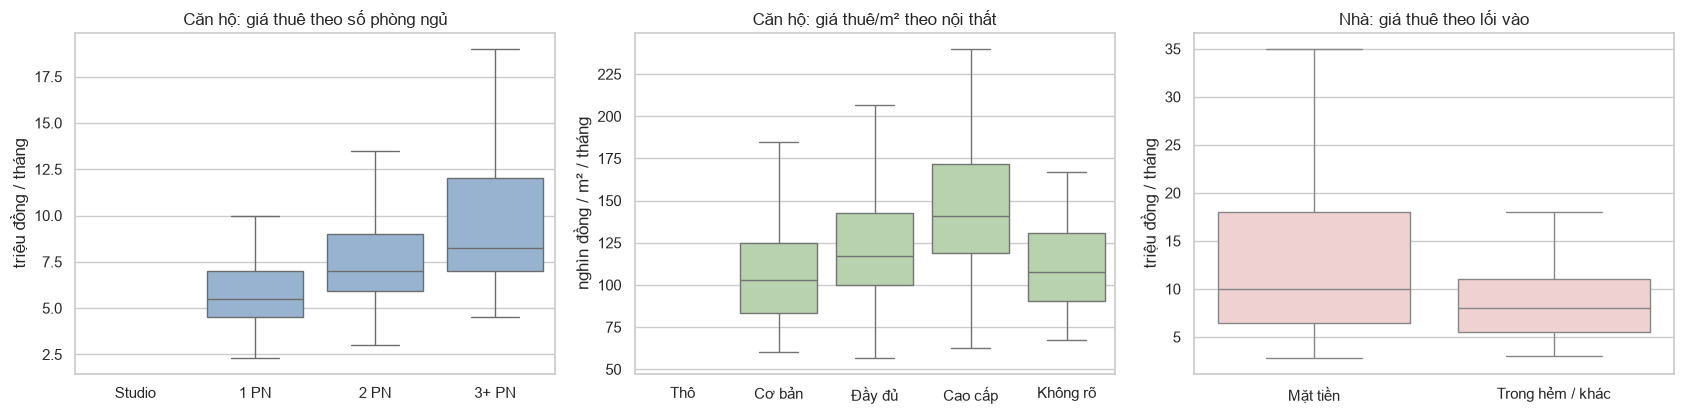

Giá thuê trung vị – căn hộ: 6.8 triệu/tháng | nhà: 8.5 triệu/tháng
Nhà – giá thuê trung vị theo lối vào (triệu/tháng): {'Mặt tiền': 10.0, 'Trong hẻm / khác': 8.0}


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
sns.boxplot(x=ch["phong_ngu"].clip(upper=3).map({0: "Studio", 1: "1 PN", 2: "2 PN", 3: "3+ PN"}), y=ch["gia_ty"], order=["Studio", "1 PN", "2 PN", "3+ PN"],
            ax=axes[0], showfliers=False, color="#8fb3d9"); axes[0].set(title="Căn hộ: giá thuê theo số phòng ngủ", xlabel="", ylabel="triệu đồng / tháng")
noi_that = ch["noi_that_cap"].map({0: "Thô", 1: "Cơ bản", 2: "Đầy đủ", 3: "Cao cấp"}).fillna("Không rõ")
sns.boxplot(x=noi_that, y=ch["gia_ty"] * 1000 / ch["dt_dat"], order=["Thô", "Cơ bản", "Đầy đủ", "Cao cấp", "Không rõ"], ax=axes[1], showfliers=False, color="#b6d7a8")
axes[1].set(title="Căn hộ: giá thuê/m² theo nội thất", xlabel="", ylabel="nghìn đồng / m² / tháng")
loai = np.where(nha["mat_tien_duong"] == 1, "Mặt tiền", "Trong hẻm / khác")
sns.boxplot(x=loai, y=nha["gia_ty"], ax=axes[2], showfliers=False, color="#f4cccc"); axes[2].set(title="Nhà: giá thuê theo lối vào", xlabel="", ylabel="triệu đồng / tháng")
plt.tight_layout(); plt.show()
print("Giá thuê trung vị – căn hộ:", round(ch["gia_ty"].median(), 1), "triệu/tháng | nhà:", round(nha["gia_ty"].median(), 1), "triệu/tháng")
print("Nhà – giá thuê trung vị theo lối vào (triệu/tháng):", nha.groupby(loai)["gia_ty"].median().round(1).to_dict())

**Quan sát:** giá thuê căn hộ tăng theo số phòng ngủ và mức nội thất (căn đầy đủ nội thất cho thuê đắt hơn rõ). Nhà mặt tiền cho thuê đắt hơn nhà trong hẻm (trung vị in ở dòng cuối ô trên) vì có thể dùng để **kinh doanh**.

## Bước 3: Mô hình giá thuê
Cùng quy trình hai notebook định giá: tập test giữ riêng 20% số nhóm; kiểm định chéo 5-fold lặp 3 lần **chia theo nhóm** trên tập train; chọn mô hình **đơn giản nhất không kém mô hình tốt nhất một cách có ý nghĩa**.

**Phần A – mô hình cơ bản của môn học** (giống Phần A của notebook chính): hồi quy tuyến tính (TH6), cây quyết định (bài giảng 3, TH9/TH10), KNN (TH10), SVR (bài giảng 6), mạng nơ-ron MLP (bài giảng 4), Random Forest (TH10). Chỉ dùng thông số của chính căn (không dùng giá thuê khu vực); mục tiêu log(giá thuê); siêu tham số và mô hình chọn bằng `GridSearchCV` với kiểm định chéo 5-fold trên tập train (TH11).

**Phần B – nâng cao:**

| Mô hình | Ý tưởng |
|---|---|
| Baseline | Giá thuê/m² trung vị của dự án (căn hộ) hoặc của phường (nhà) × diện tích |
| Ridge | Hồi quy tuyến tính trên log(giá thuê/m²), cộng giá thuê khu vực |
| LightGBM | Gradient boosting |

Đặc trưng: diện tích, phòng ngủ, WC, nội thất, (căn hộ: tầng, nhà ở xã hội; nhà: số tầng, ngang, dài, mặt tiền, lối vào, độ rộng hẻm), tọa độ, khoảng cách trung tâm, **giá thuê khu vực** (12 căn gần nhất, cùng phường, cùng dự án / tuyến đường – chỉ tính trên tập học).

In [4]:
import json
class BaselineThue(BaseEstimator, RegressorMixin):
    # giá thuê/m² trung vị của dự án (nếu >= 3 tin) -> của phường -> toàn bộ, nhân diện tích
    def fit(self, X, y):
        u = pd.Series(np.asarray(y) - np.log(X["dt_dat"].to_numpy()), index=X.index); self.g_ = u.median()
        g = u.groupby(X["duong"]); self.d_ = g.median()[g.size() >= 3]
        self.p_ = u.groupby(X["quan"] + "|" + X["phuong"].astype(str)).median(); return self
    def predict(self, X):
        k = X["quan"] + "|" + X["phuong"].astype(str)
        return X["duong"].map(self.d_).fillna(k.map(self.p_)).fillna(self.g_).to_numpy() + np.log(X["dt_dat"].to_numpy())

DT_CH = ["log_dt", "phong_ngu", "so_wc", "tang_so", "noi_that_cap", "noxh", "lat", "lon", "kc_trung_tam_km"]
DT_NHA = ["log_dt", "ngang", "dai", "so_tang", "dt_san", "ty_le_san", "phong_ngu", "so_wc", "mat_tien_duong", "cap_loi_vao", "hem_rong",
          "noi_that", "lat", "lon", "kc_trung_tam_km"]
lgb = lambda: LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=15, min_child_samples=10, subsample=0.8, subsample_freq=1,
                            colsample_bytree=0.7, verbose=-1, random_state=0, n_jobs=1)

def mo_hinh(dt, tang_bac):
    return {"Baseline (giá thuê/m² khu vực)": lambda: BaselineThue(),
            "Ridge": lambda: MoHinhGia(RidgeCV(alphas=np.logspace(-2, 3, 30)), dt, chuan_hoa=True, muc_tieu="don_gia", tang_bac=tang_bac),
            "LightGBM": lambda: MoHinhGia(lgb(), dt, muc_tieu="don_gia", tang_bac=tang_bac)}

def danh_gia(d, ten_loai, dt, tang_bac):
    _, vt = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE).split(d, groups=d["nhom"]))
    d = d.assign(tap=np.where(d.index.isin(vt), "test", "train"))
    tr, te = d[d["tap"] == "train"].reset_index(drop=True), d[d["tap"] == "test"].reset_index(drop=True)
    # Phần A: mô hình của môn học trên thông số của căn, chọn bằng kiểm định chéo trên tập train
    bang_a, tot_a, tao_a = mo_hinh_co_ban(tr, dt, baseline=BaselineThue, seed=RANDOM_STATE)
    print(f"== {ten_loai} – Phần A: kiểm định chéo 5-fold ({len(tr)} tin train; MAE trên log(giá thuê))"); display(bang_a.round(3))
    mo_hinh_a = tao_a[tot_a]().fit(tr[dt].astype(float), tr["y"])
    # Phần B
    MH = mo_hinh(dt, tang_bac)
    OOF = {k: du_doan_cheo_lap(f, tr, so_lan=SO_LAN) for k, f in MH.items()}
    bang = bang_danh_gia(tr, OOF, np.ones(len(tr), bool)).rename(columns={"MAE (tỷ)": "MAE (triệu/tháng)"}).sort_values("MAPE (%)")
    print(f"== {ten_loai} – Phần B: kiểm định chéo lặp {SO_LAN} lần ({len(tr)} tin train)"); display(bang.round(2))
    APE = {k: sai_so_tung_can(tr, P) for k, P in OOF.items()}
    uv = [k for k in MH if not k.startswith("Baseline")]
    tot = min(uv, key=lambda k: APE[k].mean())
    chon = tot
    for k in uv:                                   # đơn giản nhất mà không kém có ý nghĩa
        lo, _ = ktc_bootstrap(APE[k] - APE[tot], tr["nhom"].to_numpy()) if k != tot else (0, 0)
        if lo <= 0:
            chon = k; break
    lo, hi = ktc_bootstrap(APE["Baseline (giá thuê/m² khu vực)"] - APE[chon], tr["nhom"].to_numpy())
    print(f"Chọn: {chon} (MAPE thấp nhất: {tot}). So với baseline: giảm {np.mean(APE['Baseline (giá thuê/m² khu vực)'] - APE[chon]):.2f} điểm % (KTC 95% {lo:+.2f} … {hi:+.2f})")
    m = MH[chon]().fit(tr, tr["y"])
    bt = bang_danh_gia(te, {chon: m.predict(te), f"Phần A – {tot_a}": mo_hinh_a.predict(te[dt].astype(float)),
                            "Baseline": MH["Baseline (giá thuê/m² khu vực)"]().fit(tr, tr["y"]).predict(te)}, np.ones(len(te), bool))
    print(f"Tập test ({len(te)} tin):"); display(bt.rename(columns={"MAE (tỷ)": "MAE (triệu/tháng)"}).round(2))
    a_, b_ = bt.loc[f"Phần A – {tot_a}"], bt.loc[chon]
    chong = a_["MAPE thấp (95%)"] <= b_["MAPE cao (95%)"] and b_["MAPE thấp (95%)"] <= a_["MAPE cao (95%)"]
    nx(f'''**{ten_loai.capitalize()} – Phần A so với Phần B trên tập test:** Phần A ({tot_a}) sai {vn(a_["MAPE (%)"])}% (KTC {vn(a_["MAPE thấp (95%)"])}–{vn(a_["MAPE cao (95%)"])}%), Phần B ({chon}) sai {vn(b_["MAPE (%)"])}% (KTC {vn(b_["MAPE thấp (95%)"])}–{vn(b_["MAPE cao (95%)"])}%) → {"hai khoảng chồng nhau: chưa đủ bằng chứng Phần B tốt hơn" if chong else "hai khoảng không chồng nhau: giá thuê khu vực của Phần B cải thiện rõ"}.''')
    R = tr["y"].to_numpy() - OOF[chon]
    return {"ten": chon, "phan_a": bang_a, "MH": MH, "bang": bang, "test": bt, "khoang": hieu_chinh_khoang(R.ravel(), np.zeros(R.size, int)), "d": d}

KQ_CH = danh_gia(ch, "CĂN HỘ cho thuê", DT_CH, True)
KQ_NHA = danh_gia(nha, "NHÀ cho thuê", DT_NHA, False)

== CĂN HỘ cho thuê – Phần A: kiểm định chéo 5-fold (408 tin train; MAE trên log(giá thuê))


,Siêu tham số chọn,MAE log – phần học,MAE log – kiểm định,MAE ≈ sai số %
Random Forest (300 cây),–,0.117,0.194,21.407
SVM hồi quy (SVR),"C = 1, epsilon = 0.05",0.140,0.203,22.483
Baseline,–,NaN,0.208,23.136
KNN,n_neighbors = 5,0.171,0.224,25.072
Hồi quy tuyến tính,–,0.217,0.230,25.816
Mạng nơ-ron MLP,"alpha = 1.0, hidden_layer_sizes = (32, 16)",0.191,0.230,25.834
Cây quyết định,max_depth = 5,0.169,0.235,26.434


== CĂN HỘ cho thuê – Phần B: kiểm định chéo lặp 3 lần (408 tin train)


,MAPE (%),MAPE thấp (95%),MAPE cao (95%),MdAPE (%),Trong ±10% (%),Trong ±20% (%),MAE (triệu/tháng),R²,Số căn
Ridge,19.39,17.49,21.54,14.55,32.19,65.28,1.51,0.71,408.0
LightGBM,19.81,17.96,21.84,15.72,33.01,61.76,1.57,0.68,408.0
Baseline (giá thuê/m² khu vực),22.77,20.23,25.73,15.69,30.96,59.23,1.65,0.67,408.0


Chọn: Ridge (MAPE thấp nhất: Ridge). So với baseline: giảm 3.38 điểm % (KTC 95% +1.90 … +5.08)


Tập test (99 tin):


... (6 outputs left out)

Chọn: Ridge (MAPE thấp nhất: LightGBM). So với baseline: giảm 25.78 điểm % (KTC 95% +18.27 … +33.68)


Tập test (43 tin):


,MAPE (%),MAPE thấp (95%),MAPE cao (95%),MdAPE (%),Trong ±10% (%),Trong ±20% (%),MAE (triệu/tháng),R²,Số căn
Ridge,25.52,19.71,31.37,20.35,25.58,46.51,3.33,0.62,43.0
Phần A – Random Forest (300 cây),23.41,17.17,31.46,14.88,27.91,55.81,2.92,0.70,43.0
Baseline,43.22,31.70,58.60,35.35,11.63,30.23,5.23,0.22,43.0


**Nhà cho thuê – Phần A so với Phần B trên tập test:** Phần A (Random Forest (300 cây)) sai 23,4% (KTC 17,2–31,5%), Phần B (Ridge) sai 25,5% (KTC 19,7–31,4%) → hai khoảng chồng nhau: chưa đủ bằng chứng Phần B tốt hơn.

**Đọc kết quả:**

In [5]:
ban_ch = json.load(open(MODEL_DIR / "mo_hinh_gia_can_ho.json", encoding="utf-8"))["mo_hinh_day_du_mape"]
dg_nha = json.load(open(MODEL_DIR / "danh_gia_mo_hinh.json", encoding="utf-8"))
ban_nha = next(m["MAPE (%)"] for m in dg_nha["kiem_dinh_cheo_tdm"] if m["Mô hình"] == dg_nha["ten_mo_hinh"])
thue_ch, thue_nha = (K["bang"].loc[K["ten"], "MAPE (%)"] for K in (KQ_CH, KQ_NHA))
de_hon = lambda a, b: "**dễ dự đoán hơn**" if a < b else "**khó dự đoán hơn**"
nx(f'''- Căn hộ: giá thuê {de_hon(thue_ch, ban_ch)} giá bán (kiểm định chéo {vn(thue_ch)}% so với {vn(ban_ch)}%). Nhà phố: giá thuê {de_hon(thue_nha, ban_nha)} giá bán ({vn(thue_nha)}% so với {vn(ban_nha)}% trên Thủ Dầu Một).
- Nhà cho thuê sai {"nhiều hơn" if thue_nha > thue_ch else "ít hơn"} căn hộ cho thuê{": tin cho thuê nhà phố lẫn nhà ở với mặt bằng kinh doanh, còn căn hộ cùng dự án cho thuê giá khá đồng đều" if thue_nha > thue_ch else ""}. Giá thuê còn phụ thuộc nội thất, tình trạng nhà và thời hạn thuê mà tin thường không ghi đủ, và mô hình giá thuê không dùng mô tả tin.''')

- Căn hộ: giá thuê **khó dự đoán hơn** giá bán (kiểm định chéo 19,4% so với 13,7%). Nhà phố: giá thuê **khó dự đoán hơn** giá bán (33,5% so với 24,4% trên Thủ Dầu Một).
- Nhà cho thuê sai nhiều hơn căn hộ cho thuê: tin cho thuê nhà phố lẫn nhà ở với mặt bằng kinh doanh, còn căn hộ cùng dự án cho thuê giá khá đồng đều. Giá thuê còn phụ thuộc nội thất, tình trạng nhà và thời hạn thuê mà tin thường không ghi đủ, và mô hình giá thuê không dùng mô tả tin.

## Bước 4: Tỷ suất cho thuê của các căn đang rao bán
Huấn luyện lại mô hình giá thuê đã chọn trên **toàn bộ** tin cho thuê, rồi ước lượng giá thuê cho **mỗi căn đang rao bán** (dữ liệu sạch của 2 notebook định giá).
- **Tỷ suất cho thuê gộp (gross yield)** = 12 × giá thuê ước tính / giá rao bán. Chưa trừ chi phí (thuế, sửa chữa, thời gian trống), nên tỷ suất thực nhận thấp hơn.
- **Số năm hoàn vốn** = giá rao bán / (12 × giá thuê).

In [6]:
m_ch = KQ_CH["MH"][KQ_CH["ten"]]().fit(ch, ch["y"])
m_nha = KQ_NHA["MH"][KQ_NHA["ten"]]().fit(nha, nha["y"])

ban_ch = pd.read_csv(PROC / "can_ho_da_xu_ly.csv", dtype={"id": str})
ban_nha = pd.read_csv(PROC / "nha_da_xu_ly.csv", dtype={"id": str})
ban_ch["duong"] = ban_ch["du_an"]
ban_nha["noi_that"] = ban_nha["noi_that"].fillna(0)
ban_ch["thue_trieu"] = np.exp(m_ch.predict(ban_ch))
ban_nha["thue_trieu"] = np.exp(m_nha.predict(ban_nha))
for d in (ban_ch, ban_nha):
    d["ty_suat_pt"] = d["thue_trieu"] * 12 / (d["gia_ty"] * 1000) * 100
    d["hoan_von_nam"] = d["gia_ty"] * 1000 / (d["thue_trieu"] * 12)

tom = pd.DataFrame({
    "Căn hộ – toàn vùng": ban_ch["ty_suat_pt"].describe(percentiles=[.25, .5, .75]),
    "Căn hộ – Thủ Dầu Một": ban_ch.loc[ban_ch["tdm"] == 1, "ty_suat_pt"].describe(percentiles=[.25, .5, .75]),
    "Nhà phố – Thủ Dầu Một": ban_nha.loc[ban_nha["tdm"] == 1, "ty_suat_pt"].describe(percentiles=[.25, .5, .75]),
    "Nhà phố – Phú Hòa": ban_nha.loc[ban_nha["phu_hoa"] == 1, "ty_suat_pt"].describe(percentiles=[.25, .5, .75]),
}).T[["count", "25%", "50%", "75%"]].rename(columns={"count": "Số căn", "25%": "25% (%/năm)", "50%": "Trung vị (%/năm)", "75%": "75% (%/năm)"})
tom["Hoàn vốn trung vị (năm)"] = 100 / tom["Trung vị (%/năm)"]
display(tom.round(2))

,Số căn,25% (%/năm),Trung vị (%/năm),75% (%/năm),Hoàn vốn trung vị (năm)
Căn hộ – toàn vùng,585.0,3.03,3.62,4.64,27.60
Căn hộ – Thủ Dầu Một,119.0,4.40,5.31,6.44,18.83
Nhà phố – Thủ Dầu Một,680.0,2.27,2.97,3.82,33.67
Nhà phố – Phú Hòa,218.0,1.95,2.49,3.01,40.12


**Kiểm chứng chéo:** với các dự án căn hộ có **cả tin bán lẫn tin cho thuê**, tính tỷ suất **thẳng từ dữ liệu** = 12 × giá thuê/m² trung vị / giá bán/m² trung vị, rồi so với tỷ suất trung vị mà mô hình ước lượng cho các căn đang bán của dự án đó. Nếu hai con số gần nhau, mô hình giá thuê áp dụng cho tin bán là đáng tin.

In [7]:
thue_m2 = ch.groupby("du_an").agg(n_thue=("y", "size"), thue_m2=("gia_ty", lambda s: np.median(s / ch.loc[s.index, "dt_dat"])))
ban_m2 = ban_ch.groupby("du_an").agg(n_ban=("y", "size"), ban_m2=("don_gia", "median"), ty_suat_mo_hinh=("ty_suat_pt", "median"))
kc = thue_m2.join(ban_m2, how="inner").query("n_thue >= 5 and n_ban >= 5")
kc["ty_suat_du_lieu"] = kc["thue_m2"] * 12 / kc["ban_m2"] * 100
kc = kc.sort_values("ty_suat_du_lieu", ascending=False)
display(kc[["n_thue", "n_ban", "ty_suat_du_lieu", "ty_suat_mo_hinh"]].round(2))
r_ = np.corrcoef(kc["ty_suat_du_lieu"], kc["ty_suat_mo_hinh"])[0, 1]
print(f"{len(kc)} dự án có ≥ 5 tin bán và ≥ 5 tin thuê | tương quan giữa hai cách tính: {r_:.2f} | "
      f"chênh trung vị (mô hình − dữ liệu): {np.median(kc['ty_suat_mo_hinh'] - kc['ty_suat_du_lieu']):+.2f} điểm %")

,n_thue,n_ban,ty_suat_du_lieu,ty_suat_mo_hinh
du_an,,,,
c skyview,22,26,5.81,5.29
khu dan cu hiep thanh 3,10,7,5.52,6.16
happy one,9,6,5.10,4.46
happy one central,28,10,4.98,4.71
legacy central,11,12,4.70,5.01
the maison,6,11,4.33,3.94
charm city,20,16,4.03,3.80
the habitat,8,8,3.95,3.21
bcons garden,6,11,3.89,3.71


13 dự án có ≥ 5 tin bán và ≥ 5 tin thuê | tương quan giữa hai cách tính: 0.91 | chênh trung vị (mô hình − dữ liệu): -0.23 điểm %


**Đọc kết quả:** nếu tương quan cao và chênh lệch trung vị nhỏ, tỷ suất do mô hình ước lượng cho từng căn đang bán khớp với thực tế thị trường cho thuê của dự án đó.

## Bước 5: Tỷ suất cho thuê theo khu vực và dự án

Nhà phố – Thủ Dầu Một, theo phường:


,so_can,gia_tv,thue_tv,ty_suat
phuong,,,,
Hoà Phú,33,4.70,18.51,4.47
Tân An,10,2.39,7.85,4.22
Chánh Mỹ,94,2.92,11.14,4.05
Tương Bình Hiệp,35,2.50,7.98,3.74
Định Hoà,24,2.82,9.14,3.51
Phú Mỹ,63,3.85,11.14,3.46
Phú Lợi,52,4.39,11.03,2.92
Chánh Nghĩa,32,3.78,9.54,2.65
Hiệp An,24,2.75,6.20,2.63


Căn hộ, theo dự án (≥ 5 căn đang bán):


,ten,quan,so_can,gia_tv,thue_tv,ty_suat
du_an,,,,,,
k home new city,K Home New City,thu dau mot,10,1.03,9.23,12.28
khu can ho phu my,Khu căn hộ Phú Mỹ Bình Dương,ben cat,11,0.64,6.20,12.20
becamex hoa loi,Nhà ở xã hội Becamex Hòa Lợi,thu dau mot,6,0.40,3.18,10.17
khu dan cu hiep thanh 3,Khu dân cư Hiệp Thành 3,thu dau mot,7,1.18,6.06,6.16
c skyview,C SkyView,thu dau mot,26,2.20,9.76,5.29
legacy central,Legacy Central,thuan an,12,1.18,4.58,5.01
becamex dinh hoa,Nhà ở xã hội Becamex Định Hòa,thu dau mot,12,0.46,1.87,4.97
legacy prime,Legacy Prime,thuan an,5,1.20,4.79,4.77
happy one central,Happy One Central,thu dau mot,10,2.40,10.31,4.71


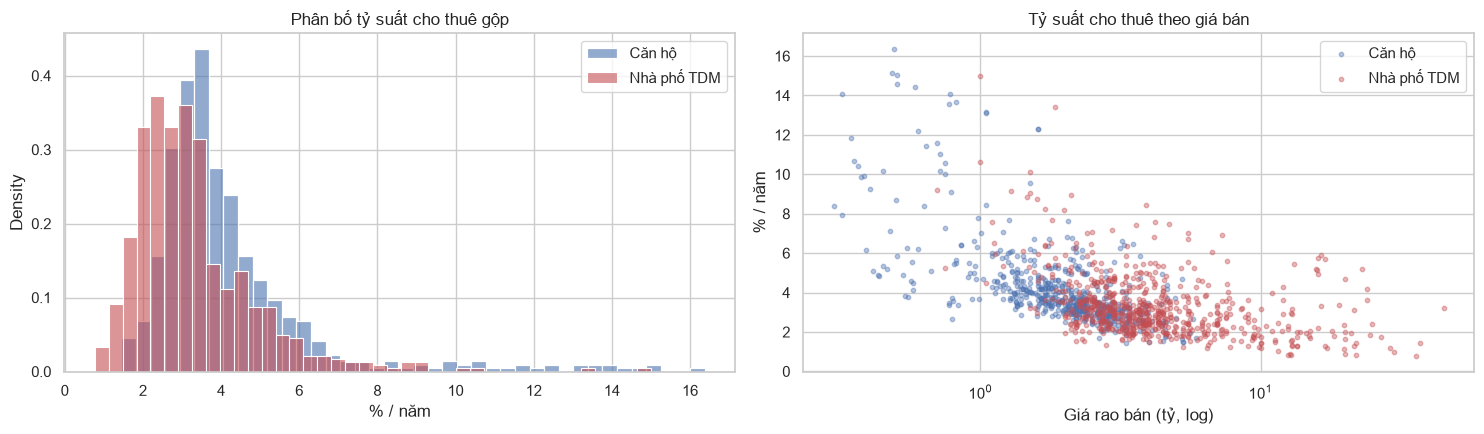

**Quan sát:**
- **Căn hộ cho tỷ suất cho thuê cao hơn nhà phố** (trung vị 3,6%/năm so với 3,0%/năm ở nhà phố Thủ Dầu Một): căn hộ dễ cho thuê (gần khu công nghiệp, khu đô thị), còn giá nhà phố chủ yếu nằm ở **giá trị đất**, giá thuê không theo kịp.
- **Căn càng đắt thì tỷ suất càng thấp** (tương quan hạng Spearman giữa giá bán và tỷ suất: -0,42 với nhà phố Thủ Dầu Một, -0,69 với căn hộ): giá bán tăng nhanh hơn giá thuê. Người mua nhà phố đắt tiền chủ yếu kỳ vọng **tăng giá đất**, không phải dòng tiền cho thuê.

In [8]:
ten_ph = {ten_phuong(p): re.sub(r"^(Phường|Xã|Thị trấn)\s*", "", p) for p in pd.concat([raw_nha["phuong"], raw_ch["phuong"]]).dropna().unique()}
ph_nha = (ban_nha[ban_nha["tdm"] == 1].groupby("phuong").agg(so_can=("y", "size"), gia_tv=("gia_ty", "median"), thue_tv=("thue_trieu", "median"), ty_suat=("ty_suat_pt", "median"))
          .query("so_can >= 8").sort_values("ty_suat", ascending=False))
ph_nha.index = ph_nha.index.map(lambda k: ten_ph.get(k, k))
print("Nhà phố – Thủ Dầu Một, theo phường:"); display(ph_nha.round(2))
da = (ban_ch.groupby("du_an").agg(ten=("du_an_goc", lambda s: s.dropna().mode()[0] if s.notna().any() else None), quan=("quan", "first"), so_can=("y", "size"),
                                 gia_tv=("gia_ty", "median"), thue_tv=("thue_trieu", "median"), ty_suat=("ty_suat_pt", "median"))
      .query("so_can >= 5").sort_values("ty_suat", ascending=False))
print("Căn hộ, theo dự án (≥ 5 căn đang bán):"); display(da.head(12).round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(ban_ch["ty_suat_pt"], bins=40, ax=axes[0], color="#4C72B0", label="Căn hộ", stat="density", alpha=0.6)
sns.histplot(ban_nha.loc[ban_nha["tdm"] == 1, "ty_suat_pt"], bins=40, ax=axes[0], color="#C44E52", label="Nhà phố TDM", stat="density", alpha=0.6)
axes[0].set(title="Phân bố tỷ suất cho thuê gộp", xlabel="% / năm"); axes[0].legend()
axes[1].scatter(ban_ch["gia_ty"], ban_ch["ty_suat_pt"], s=10, alpha=0.4, label="Căn hộ")
axes[1].scatter(ban_nha.loc[ban_nha["tdm"] == 1, "gia_ty"], ban_nha.loc[ban_nha["tdm"] == 1, "ty_suat_pt"], s=10, alpha=0.4, color="#C44E52", label="Nhà phố TDM")
axes[1].set(xscale="log", title="Tỷ suất cho thuê theo giá bán", xlabel="Giá rao bán (tỷ, log)", ylabel="% / năm"); axes[1].legend()
plt.tight_layout(); plt.show()
from scipy.stats import spearmanr
nha_tdm = ban_nha[ban_nha["tdm"] == 1]
rho_nha, rho_ch = spearmanr(nha_tdm["gia_ty"], nha_tdm["ty_suat_pt"])[0], spearmanr(ban_ch["gia_ty"], ban_ch["ty_suat_pt"])[0]
ts_ch, ts_nha = ban_ch["ty_suat_pt"].median(), nha_tdm["ty_suat_pt"].median()
nx(f'''**Quan sát:**
- {"**Căn hộ cho tỷ suất cho thuê cao hơn nhà phố**" if ts_ch > ts_nha else "**Nhà phố cho tỷ suất cho thuê không thấp hơn căn hộ**"} (trung vị {vn(ts_ch)}%/năm so với {vn(ts_nha)}%/năm ở nhà phố Thủ Dầu Một){": căn hộ dễ cho thuê (gần khu công nghiệp, khu đô thị), còn giá nhà phố chủ yếu nằm ở **giá trị đất**, giá thuê không theo kịp" if ts_ch > ts_nha else ""}.
- {"**Căn càng đắt thì tỷ suất càng thấp**" if max(rho_nha, rho_ch) < 0 else "Tỷ suất **không giảm rõ** theo giá bán"} (tương quan hạng Spearman giữa giá bán và tỷ suất: {vn(rho_nha, 2)} với nhà phố Thủ Dầu Một, {vn(rho_ch, 2)} với căn hộ){": giá bán tăng nhanh hơn giá thuê. Người mua nhà phố đắt tiền chủ yếu kỳ vọng **tăng giá đất**, không phải dòng tiền cho thuê" if max(rho_nha, rho_ch) < 0 else ""}.''')

- Tỷ suất ở đây là **gộp**. Sau khi trừ thuế cho thuê, phí quản lý, sửa chữa và thời gian nhà trống, tỷ suất thực nhận thường thấp hơn 1–2 điểm %.

## Bước 6: Lưu mô hình và kết quả
- `model/mo_hinh_gia_thue.joblib`: hai mô hình giá thuê + phân vị sai số (khoảng 80%).
- `model/gia_thue_web.json`: bảng giá thuê/m² theo dự án và phường (cho trang demo, trợ lý hỏi đáp).
- `ket_qua/ty_suat_cho_thue.csv`: giá thuê ước tính, tỷ suất, số năm hoàn vốn của từng căn đang rao bán ở Thủ Dầu Một.

In [9]:
import json, joblib
joblib.dump({"can_ho": m_ch, "nha": m_nha, "ten": {"can_ho": KQ_CH["ten"], "nha": KQ_NHA["ten"]},
             "khoang": {"can_ho": KQ_CH["khoang"], "nha": KQ_NHA["khoang"]}, "ngay_du_lieu": str(raw_nha["ngay_thu_thap"].iloc[0])},
            MODEL_DIR / "mo_hinh_gia_thue.joblib")

# Bảng cho web: log giá thuê/m² theo dự án (co về phường khi ít tin) và theo phường; tỷ suất trung vị theo dự án/phường
def bang_m2(d, khoa, m=3.0):
    u = np.log(d["gia_ty"] / d["dt_dat"]); g = float(u.median())
    ph = u.groupby(d["quan"] + "|" + d["phuong"].astype(str)).agg(["sum", "count"]); ph_v = ((ph["sum"] + m * g) / (ph["count"] + m)).to_dict()
    out = {"toan_vung": round(g, 4), "phuong": {k: round(v, 4) for k, v in ph_v.items()}}
    if khoa:
        dd = pd.DataFrame({"u": u, "k": d[khoa], "ph": d["quan"] + "|" + d["phuong"].astype(str)}).dropna(subset=["k"])
        out["du_an"] = {k: round(float((x["u"].sum() + m * ph_v.get(next(iter(x["ph"].mode()), None), g)) / (len(x) + m)), 4) for k, x in dd.groupby("k")}
        out["so_tin_du_an"] = dd.groupby("k").size().astype(int).to_dict()
    return out
web = {"can_ho": bang_m2(ch, "du_an"), "nha": bang_m2(nha, None),
       "ty_suat_tv": {"can_ho": round(float(ban_ch["ty_suat_pt"].median()), 2), "nha_tdm": round(float(ban_nha.loc[ban_nha["tdm"] == 1, "ty_suat_pt"].median()), 2)},
       "ty_suat_phuong_nha": {k: round(float(v), 2) for k, v in ban_nha[ban_nha["tdm"] == 1].groupby("phuong")["ty_suat_pt"].median().items()},
       "ty_suat_du_an": {k: round(float(v), 2) for k, v in ban_ch.groupby("du_an")["ty_suat_pt"].median().items()},
       "mape": {"can_ho": round(float(KQ_CH["bang"].loc[KQ_CH["ten"], "MAPE (%)"]), 1), "nha": round(float(KQ_NHA["bang"].loc[KQ_NHA["ten"], "MAPE (%)"]), 1)},
       "so_tin": {"can_ho": len(ch), "nha": len(nha)}, "ngay_du_lieu": str(raw_nha["ngay_thu_thap"].iloc[0])}
json.dump(web, open(MODEL_DIR / "gia_thue_web.json", "w", encoding="utf-8"), ensure_ascii=False)

cot = ["id", "nguon", "url", "phuong", "gia_ty", "thue_trieu", "ty_suat_pt", "hoan_von_nam"]
pd.concat([ban_nha.loc[ban_nha["tdm"] == 1, cot].assign(loai="Nhà phố", du_an=None, dien_tich_m2=ban_nha["dt_dat"]),
           ban_ch.loc[ban_ch["tdm"] == 1, cot + ["du_an_goc"]].rename(columns={"du_an_goc": "du_an"}).assign(loai="Căn hộ", dien_tich_m2=ban_ch["dt_dat"])]) \
  .round({"thue_trieu": 2, "ty_suat_pt": 2, "hoan_von_nam": 1}).to_csv(KET_QUA / "ty_suat_cho_thue.csv", index=False, encoding="utf-8-sig")
# lưu giá thuê ước tính vào dữ liệu đã xử lý để trang demo dùng
for d, f in [(ban_nha, "nha_da_xu_ly.csv"), (ban_ch, "can_ho_da_xu_ly.csv")]:
    goc = pd.read_csv(PROC / f, dtype={"id": str})
    goc["thue_uoc_luong_trieu"] = d["thue_trieu"].round(2).values; goc["ty_suat_cho_thue_pt"] = d["ty_suat_pt"].round(2).values
    goc.to_csv(PROC / f, index=False, encoding="utf-8-sig")
cot_t = ["id", "url", "tieu_de", "gia_ty", "dt_dat", "phong_ngu", "quan", "phuong", "lat", "lon", "duong"]
pd.concat([ch[cot_t].assign(loai="Căn hộ"), nha[cot_t].assign(loai="Nhà")]).rename(columns={"gia_ty": "thue_trieu_thang"})   .to_csv(PROC / "thue_da_xu_ly.csv", index=False, encoding="utf-8-sig")
print("Đã lưu:", "model/mo_hinh_gia_thue.joblib, model/gia_thue_web.json, ket_qua/ty_suat_cho_thue.csv, data/processed/thue_da_xu_ly.csv")

Đã lưu: model/mo_hinh_gia_thue.joblib, model/gia_thue_web.json, ket_qua/ty_suat_cho_thue.csv, data/processed/thue_da_xu_ly.csv


## Kết luận
- Mô hình giá thuê học trên **tin cho thuê thật** (căn hộ và nhà phố), đánh giá bằng cùng quy trình khắt khe như hai mô hình định giá (sai số ở Bước 3).
- **Phần A** dùng đúng các mô hình của môn học trên thông số của căn; **Phần B** thêm giá thuê khu vực. Hai phần được so trên cùng tập test ở Bước 3.
- Áp mô hình cho từng căn đang rao bán cho ra **tỷ suất cho thuê gộp** và **số năm hoàn vốn**. Tỷ suất của mô hình được kiểm chứng chéo với tỷ suất tính thẳng từ dữ liệu ở các dự án có cả tin bán lẫn tin thuê.
- Kết luận đầu tư từ dữ liệu (tỷ suất căn hộ so với nhà phố, tỷ suất theo mức giá) được in kèm số liệu ở Bước 5.

**Hạn chế:** giá thuê cũng là **giá rao**; tỷ suất là **gộp** (chưa trừ chi phí, thời gian trống); tin cho thuê nhà phố lẫn cả mặt bằng kinh doanh.